In [4]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import missingno as ms
import glob
%matplotlib inline


# data acquestion

In [46]:

# List of your 20 company symbols or CSV filenames
tickers = ['NABIL', 'EBL', 'NIMB', 'ADBL', 'NTC', 'NLIC', 'LICN', 'AHPC', 
           'CHCL', 'SHPC', 'GBIME', 'SCB', 'HDL', 'STC', 'NFS', 'CIT', 
           'APHL', 'BBC', 'CZBIL', 'KBL']


dfs = []
for ticker in tickers:
    # Read individual CSV file
    df = pd.read_csv(f"{ticker}.csv")
    
    # Add a column to identify the company
    df['Company'] = ticker
    
    # Ensure Date column is in datetime format
    df[ 'published_date'] = pd.to_datetime(df['published_date'])
    
    dfs.append(df)

# Combine all dataframes into a single master dataframe
master_df = pd.concat(dfs, ignore_index=True)

# Sort by Date and Company
master_df = master_df.sort_values(by=[ 'published_date','Company'], ascending= False).reset_index(drop=True)

print(master_df.head())

  published_date    open    high     low   close  per_change  traded_quantity  \
0     2026-10-16  5597.0  5597.0  5543.1  5591.0        0.56            347.0   
1     2026-10-16   527.9   536.0   527.0   535.0        1.13          40550.0   
2     2026-10-16   672.0   679.8   672.0   679.0        0.15          11819.0   
3     2026-10-16   920.0   925.0   915.0   920.0        1.10          19118.0   
4     2026-10-16   740.0   750.0   737.0   743.0       -0.12          12698.0   

   traded_amount  status Company  
0      1930122.3      -1     STC  
1     21621875.2       1    SHPC  
2      8001423.0       1     SCB  
3     17559337.2       0     NTC  
4      9461824.6       1    NLIC  


# data filter

In [47]:
master_df.head()

,published_date,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company
0,2026-10-16,5597.0,5597.0,5543.1,5591.0,0.56,347.0,1930122.3,-1,STC
1,2026-10-16,527.9,536.0,527.0,535.0,1.13,40550.0,21621875.2,1,SHPC
2,2026-10-16,672.0,679.8,672.0,679.0,0.15,11819.0,8001423.0,1,SCB
3,2026-10-16,920.0,925.0,915.0,920.0,1.10,19118.0,17559337.2,0,NTC
4,2026-10-16,740.0,750.0,737.0,743.0,-0.12,12698.0,9461824.6,1,NLIC


In [48]:
master_df.shape

(57496, 10)

In [49]:
master_df.describe().T

,count,mean,min,25%,50%,75%,max,std
published_date,57496,2019-05-22 06:20:09.684152,1995-07-20 00:00:00,2015-08-27 00:00:00,2019-11-19 12:00:00,2023-07-05 00:00:00,2026-10-16 00:00:00,NaN
open,57496.0,1193.741768,88.0,350.0,661.0,1550.0,13320.0,1330.992196
high,57496.0,1209.603728,0.0,354.9,668.85,1570.0,13780.0,1352.147588
low,57496.0,1176.532949,0.0,343.0,653.0,1530.0,12501.0,1309.397306
close,57496.0,1192.533279,0.0,349.0,660.0,1550.0,13317.0,1329.325512
per_change,57482.0,0.069574,-76.34,-0.94,0.0,0.8,330.48,2.873791
traded_quantity,57496.0,39454.40582,1.0,2355.0,9804.0,34580.25,3546853.0,102140.461573
traded_amount,57496.0,22892184.21299,0.0,2036900.75,7550548.0,21732026.9,1757930386.0,52478159.808344
status,57496.0,-0.086754,-1.0,-1.0,0.0,0.0,1.0,0.757779


In [50]:
master_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 57496 entries, 0 to 57495
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   published_date   57496 non-null  datetime64[us]
 1   open             57496 non-null  float64       
 2   high             57496 non-null  float64       
 3   low              57496 non-null  float64       
 4   close            57496 non-null  float64       
 5   per_change       57482 non-null  float64       
 6   traded_quantity  57496 non-null  float64       
 7   traded_amount    57496 non-null  float64       
 8   status           57496 non-null  int64         
 9   Company          57496 non-null  str           
dtypes: datetime64[us](1), float64(7), int64(1), str(1)
memory usage: 4.4 MB


In [168]:
master_df.isna().sum()

open               0
high               0
low                0
close              0
per_change         0
traded_quantity    0
traded_amount      0
status             0
Company            0
year               0
month              0
day                0
per_day_change     0
dtype: int64

#null value
-> per_change - 14

<Axes: >

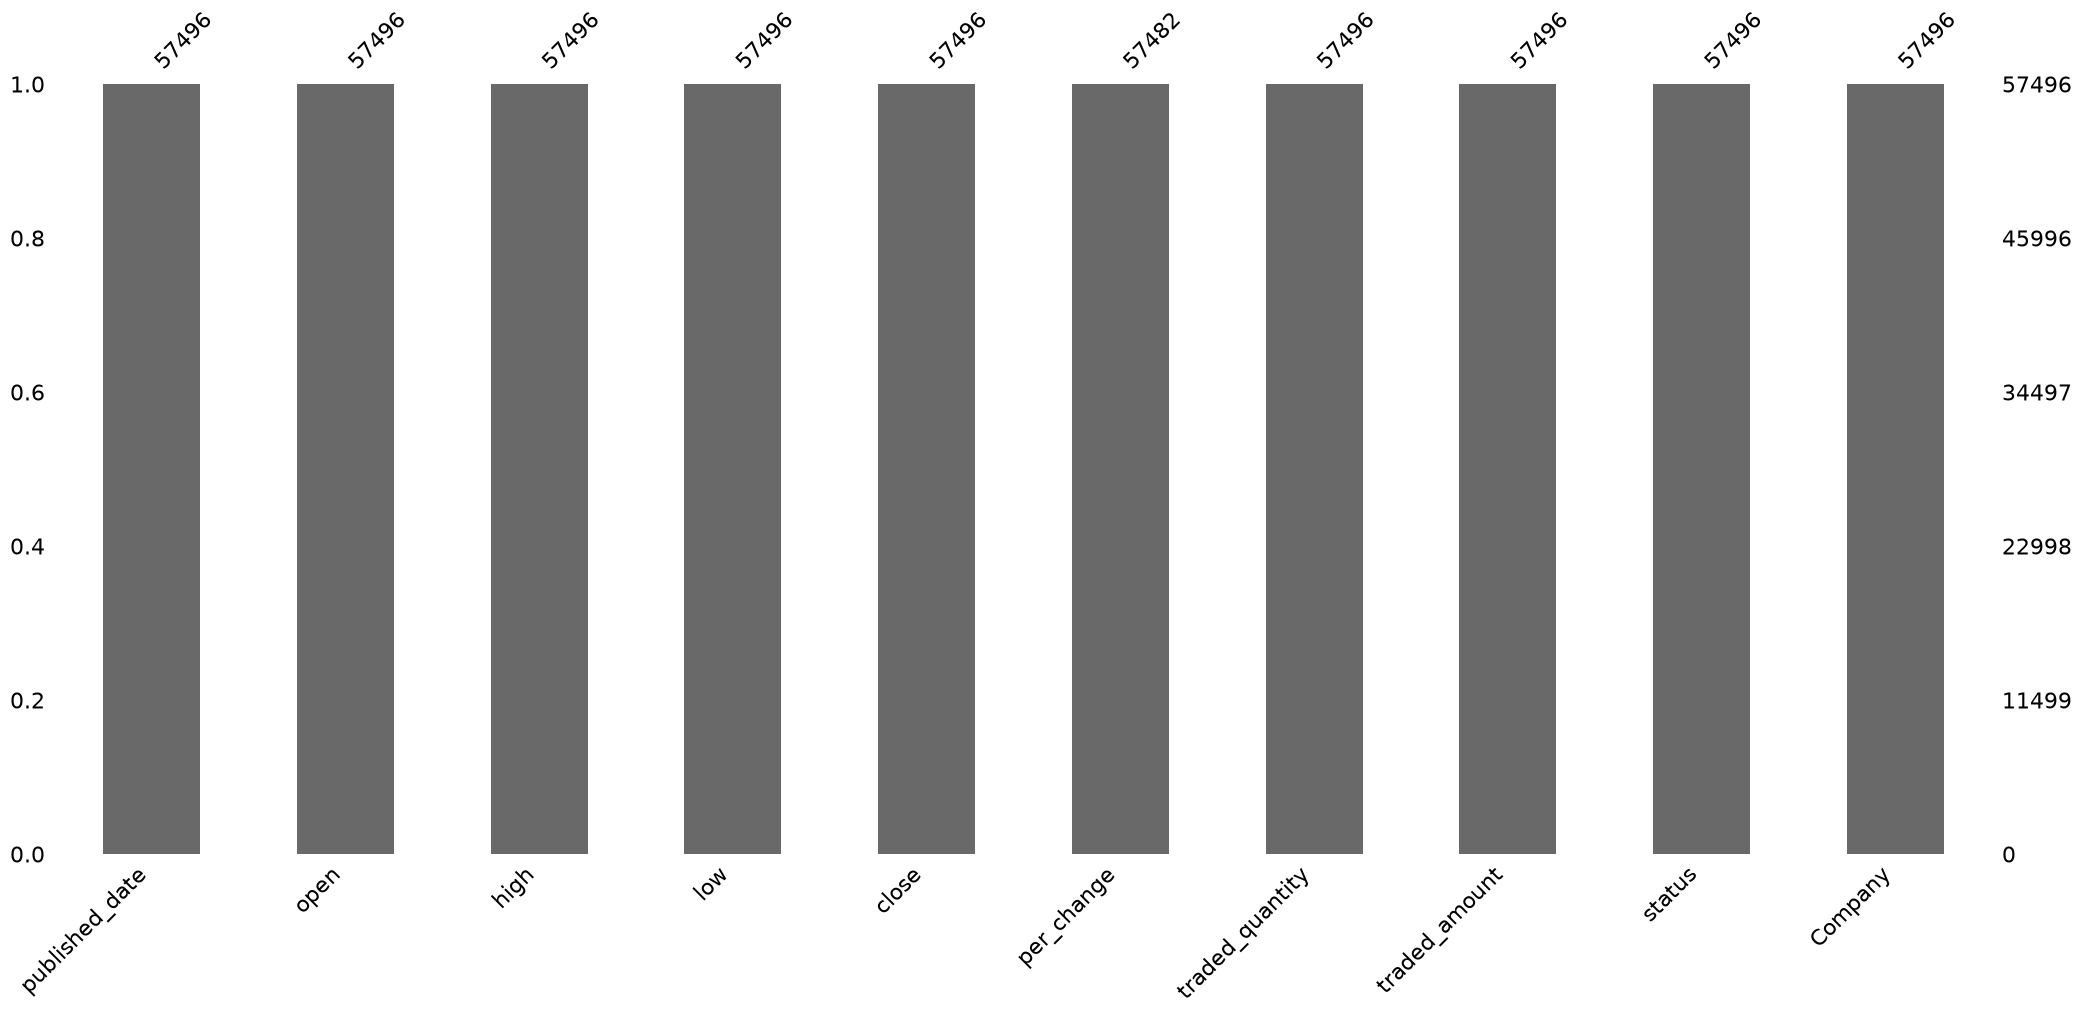

In [52]:
ms.bar(master_df)

<Axes: >

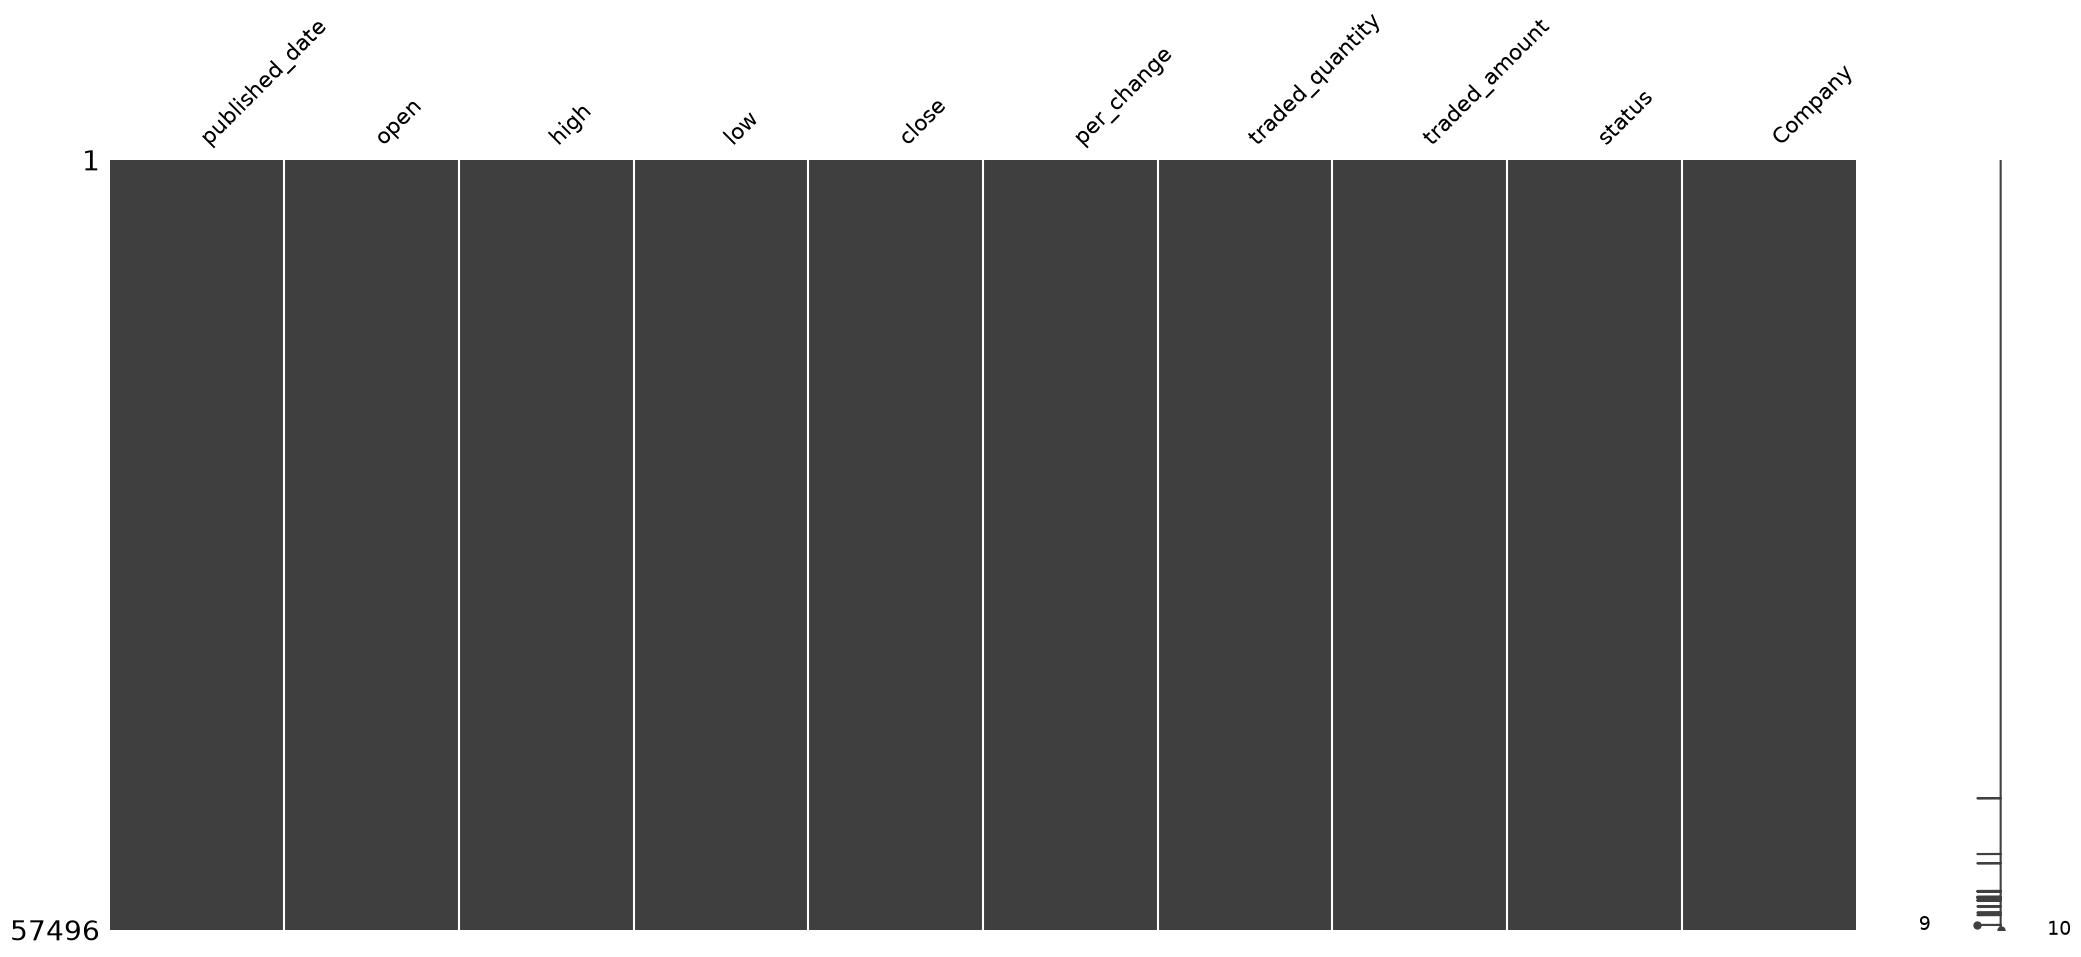

In [53]:
ms.matrix(master_df)

In [54]:
master_df['Company'].value_counts()

Company
CHCL     4479
CZBIL    3929
AHPC     3779
ADBL     3679
NTC      3539
SCB      3529
NABIL    3529
EBL      3529
NLIC     3379
KBL      3337
LICN     3279
CIT      3079
SHPC     2879
GBIME    2785
BBC      2386
HDL      2249
STC      1627
NFS      1579
NIMB      838
APHL       87
Name: count, dtype: int64

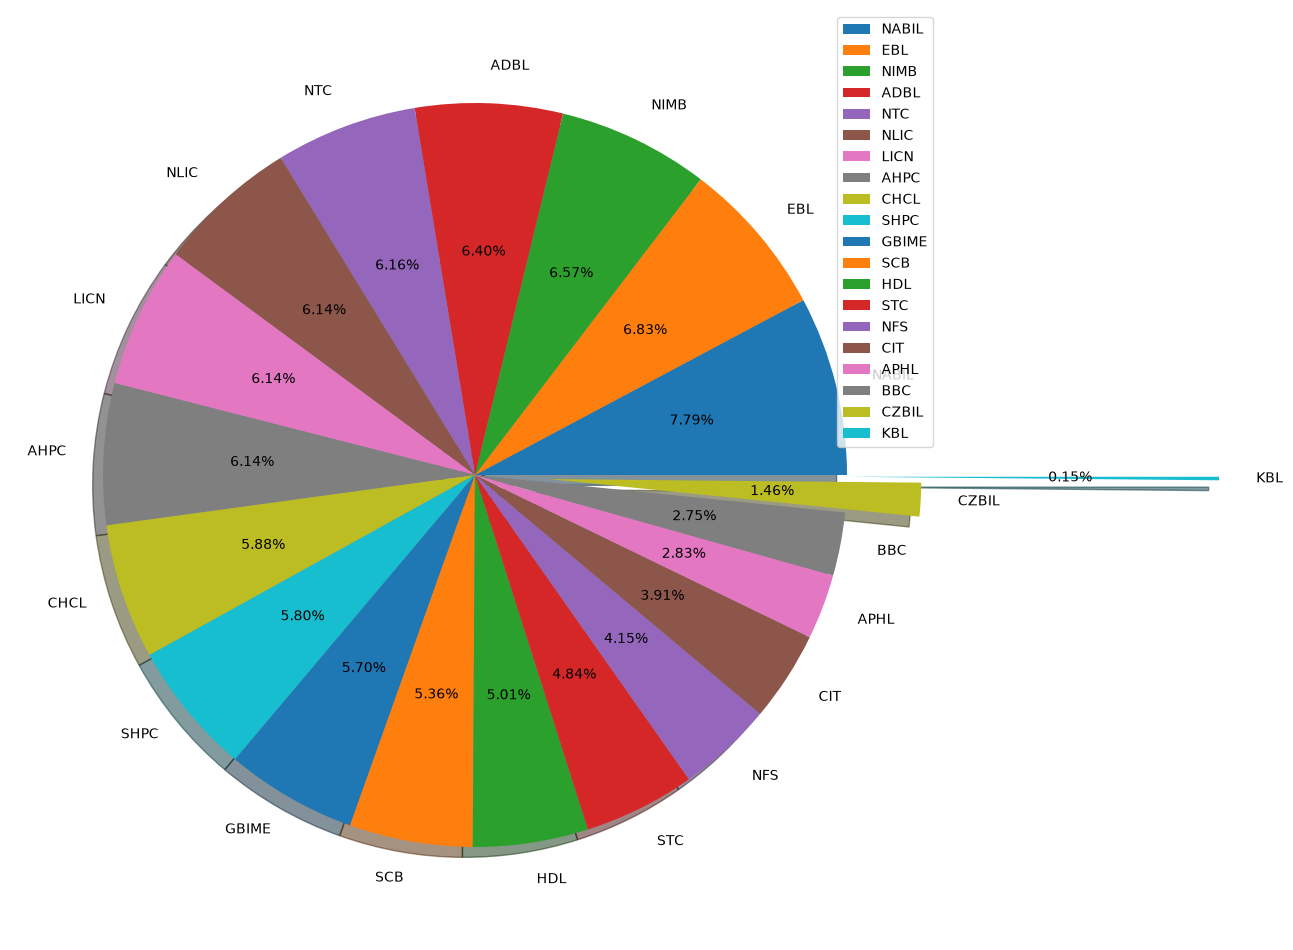

In [55]:
plt.figure(figsize=(12, 15))
plt.pie(
    master_df['Company'].value_counts(), 
    labels=tickers, 
    autopct='%1.2f%%',
    shadow=True, 
    explode = [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.2,1]
)
plt.legend(loc = 'upper right')

plt.show()

In [56]:
pd.to_datetime(master_df['published_date'], yearfirst= True)

0       2026-10-16
1       2026-10-16
2       2026-10-16
3       2026-10-16
4       2026-10-16
           ...    
57491   1995-08-06
57492   1995-08-02
57493   1995-07-30
57494   1995-07-26
57495   1995-07-20
Name: published_date, Length: 57496, dtype: datetime64[us]

In [59]:
dt_series = pd.to_datetime(master_df['published_date'], errors='coerce')

master_df['year'] = dt_series.dt.year
master_df['month'] = dt_series.dt.month
master_df['day'] = dt_series.dt.day

In [68]:
master_df


,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,month,day
0,5597.0,5597.0,5543.1,5591.0,0.56,347.0,1930122.3,-1,STC,2026,10,16
1,527.9,536.0,527.0,535.0,1.13,40550.0,21621875.2,1,SHPC,2026,10,16
2,672.0,679.8,672.0,679.0,0.15,11819.0,8001423.0,1,SCB,2026,10,16
3,920.0,925.0,915.0,920.0,1.10,19118.0,17559337.2,0,NTC,2026,10,16
4,740.0,750.0,737.0,743.0,-0.12,12698.0,9461824.6,1,NLIC,2026,10,16
...,...,...,...,...,...,...,...,...,...,...,...,...
57491,2501.0,2500.0,2500.0,2500.0,0.00,40.0,0.0,0,BBC,1995,8,6
57492,2500.0,2501.0,2501.0,2501.0,0.00,18.0,0.0,0,BBC,1995,8,2
57493,2442.0,2500.0,2500.0,2500.0,0.00,200.0,0.0,0,BBC,1995,7,30
57494,2220.0,2442.0,2442.0,2442.0,0.00,150.0,0.0,0,BBC,1995,7,26


In [62]:
#drop published date
master_df.drop(columns=['published_date'], inplace =True)

In [71]:
master_df.groupby('year')[['Company', 'traded_amount']].sum()

,Company,traded_amount
year,,
1995,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.000000e+00
1996,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.000000e+00
1997,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.000000e+00
1998,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.000000e+00
1999,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.000000e+00
2000,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.000000e+00
2001,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBC,0.000000e+00
2002,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBC,0.000000e+00
2003,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.000000e+00


In [80]:
#create seperate dataframe of year 2011
# If your 'year' column is already an integer:
df_before_2011 = master_df[master_df['year'] < 2011].reset_index()

In [85]:
df_before_2011.groupby('year')[['Company', 'traded_amount']].sum()

,Company,traded_amount
year,,
1995,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.0
1996,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.0
1997,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.0
1998,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.0
1999,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.0
2000,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.0
2001,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBC,0.0
2002,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBC,0.0
2003,BBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCBBCB...,0.0


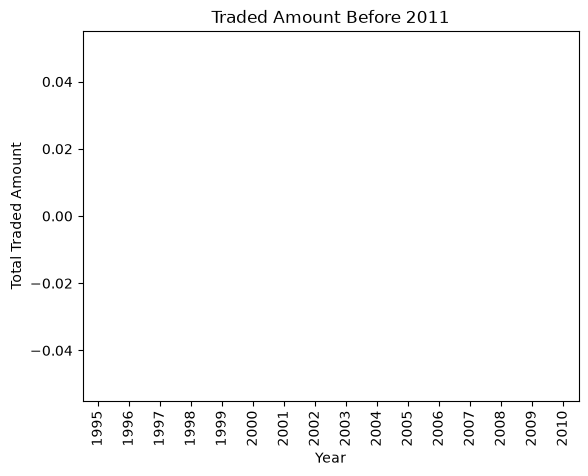

In [86]:

# Group by year, select the numeric column, sum it, and plot
df_before_2011.groupby('year')['traded_amount'].sum().plot(kind='bar')

plt.xlabel('Year')
plt.ylabel('Total Traded Amount')
plt.title('Traded Amount Before 2011')
plt.show()

In [82]:
#drop rows before 2011
master_df = master_df[master_df['year'] > 2010].copy()

In [83]:
master_df

,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,month,day
0,5597.0,5597.0,5543.1,5591.0,0.56,347.0,1930122.3,-1,STC,2026,10,16
1,527.9,536.0,527.0,535.0,1.13,40550.0,21621875.2,1,SHPC,2026,10,16
2,672.0,679.8,672.0,679.0,0.15,11819.0,8001423.0,1,SCB,2026,10,16
3,920.0,925.0,915.0,920.0,1.10,19118.0,17559337.2,0,NTC,2026,10,16
4,740.0,750.0,737.0,743.0,-0.12,12698.0,9461824.6,1,NLIC,2026,10,16
...,...,...,...,...,...,...,...,...,...,...,...,...
55504,137.0,131.0,124.0,131.0,-4.38,4755.0,0.0,0,ADBL,2011,1,3
55505,260.0,261.0,250.0,250.0,-3.85,680.0,0.0,0,CZBIL,2011,1,2
55506,950.0,950.0,945.0,950.0,0.00,870.0,0.0,0,CHCL,2011,1,2
55507,447.0,449.0,439.0,439.0,-1.79,466.0,0.0,0,AHPC,2011,1,2


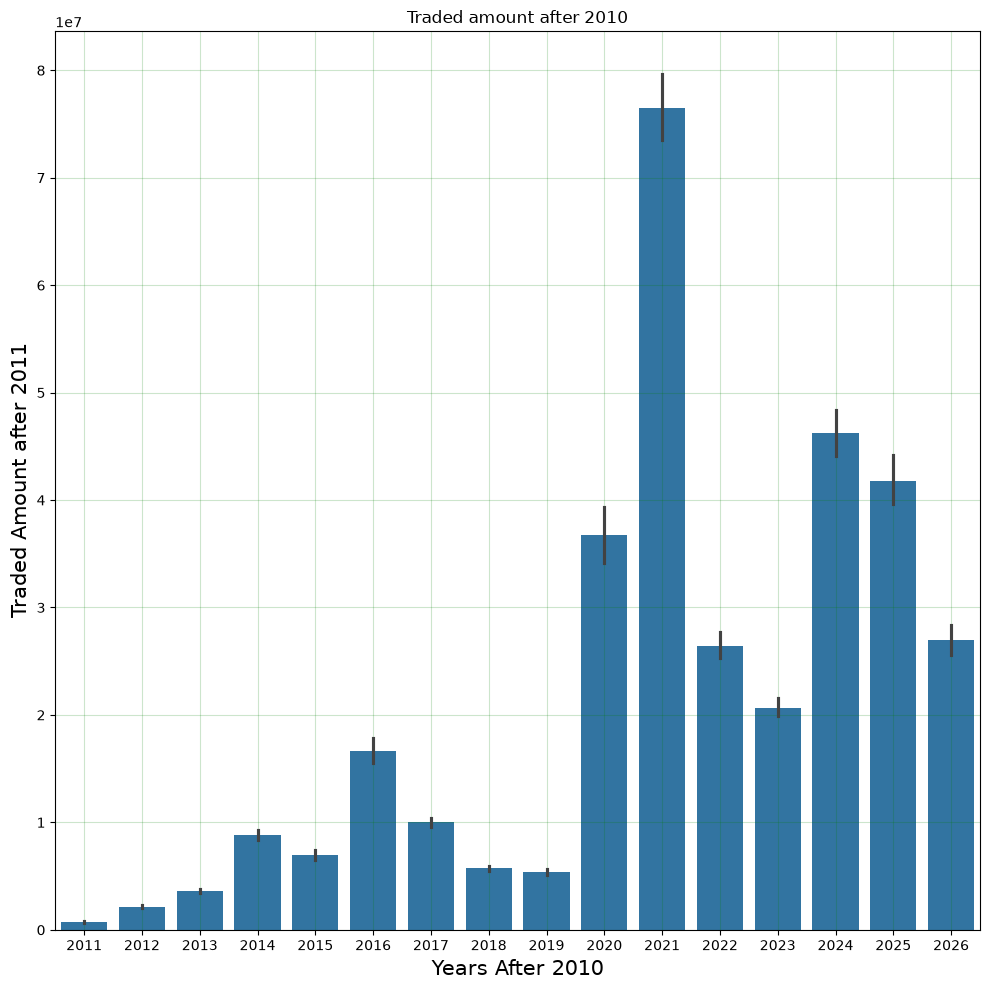

In [106]:
plt.figure(figsize=(10,10))

sns.barplot(data = master_df, x = 'year', y = 'traded_amount')
plt.xlabel('Years After 2010', fontsize = 15)
plt.ylabel(
     'Traded Amount after 2011',
     fontsize = 15
    
)
plt.title('Traded amount after 2010')
plt.grid(c= 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

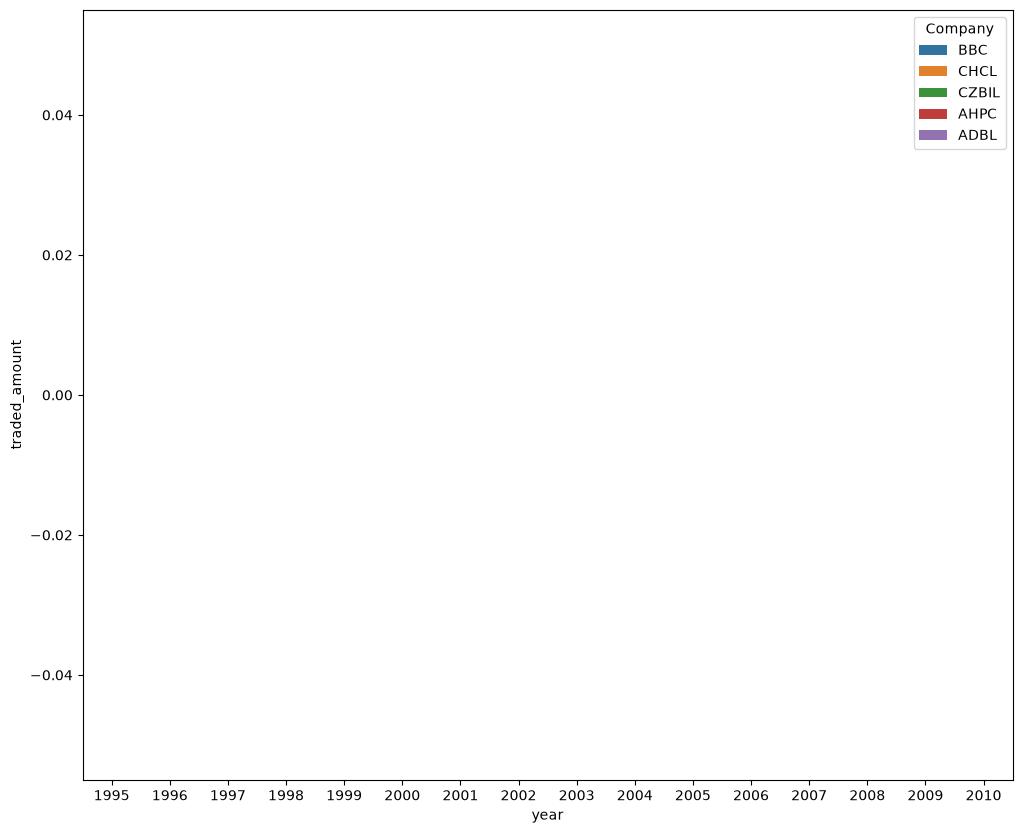

In [111]:
plt.figure(figsize=(12,10))
sns.barplot(data = df_before_2011, x = 'year', 
            y = 'traded_amount',
            hue = 'Company')
plt.show()

/tmp/ipykernel_42922/2840600750.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=master_df, x='Company', y='traded_amount', palette=twenty_colors)


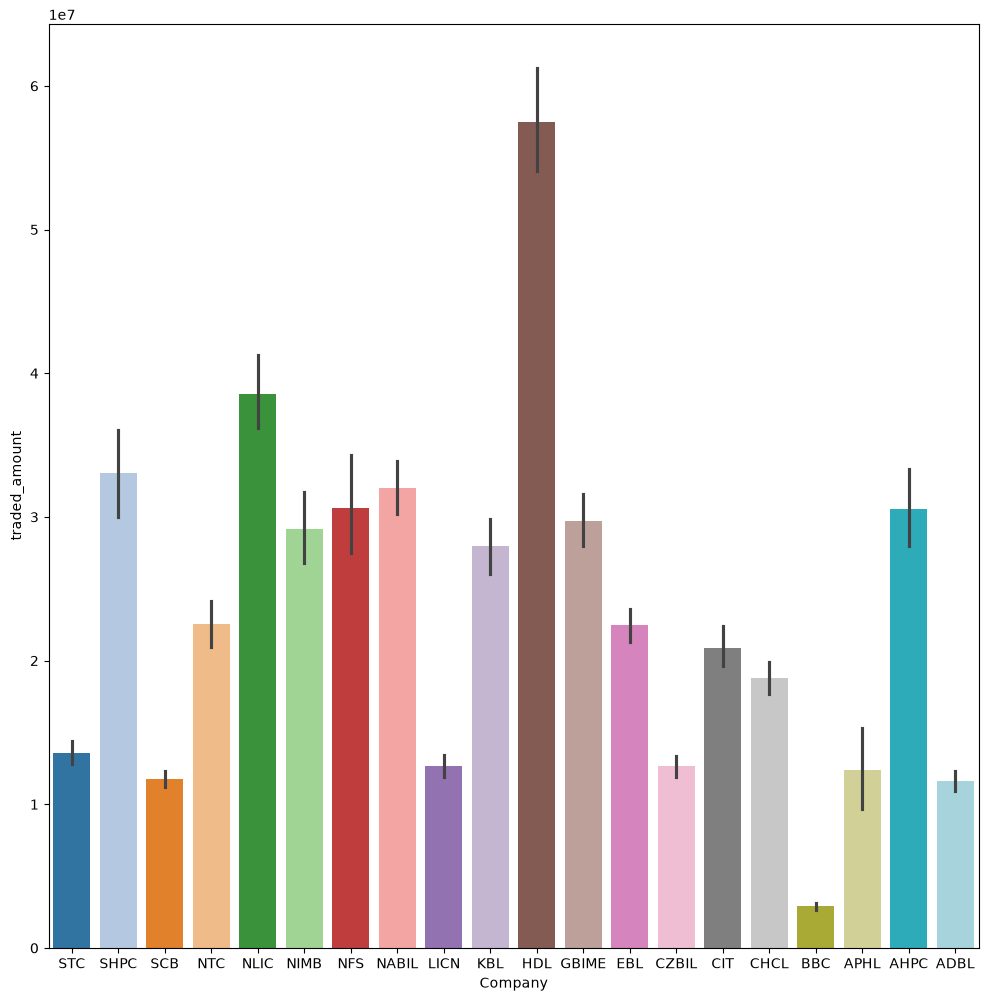

In [118]:
#ompany traded amount after 2010
twenty_colors = [
    '#1f77b4', '#aec7e8', '#ff7f0e', '#ffbb78', '#2ca02c', 
    '#98df8a', '#d62728', '#ff9896', '#9467bd', '#c5b0d5', 
    '#8c564b', '#c49c94', '#e377c2', '#f7b6d2', '#7f7f7f', 
    '#c7c7c7', '#bcbd22', '#dbdb8d', '#17becf', '#9edae5'
]
plt.figure(figsize = (12, 12))
sns.barplot(data=master_df, x='Company', y='traded_amount', palette=twenty_colors)
plt.show()

/tmp/ipykernel_42922/1823875919.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=master_df, x='Company', y='traded_quantity', palette=twenty_colors)


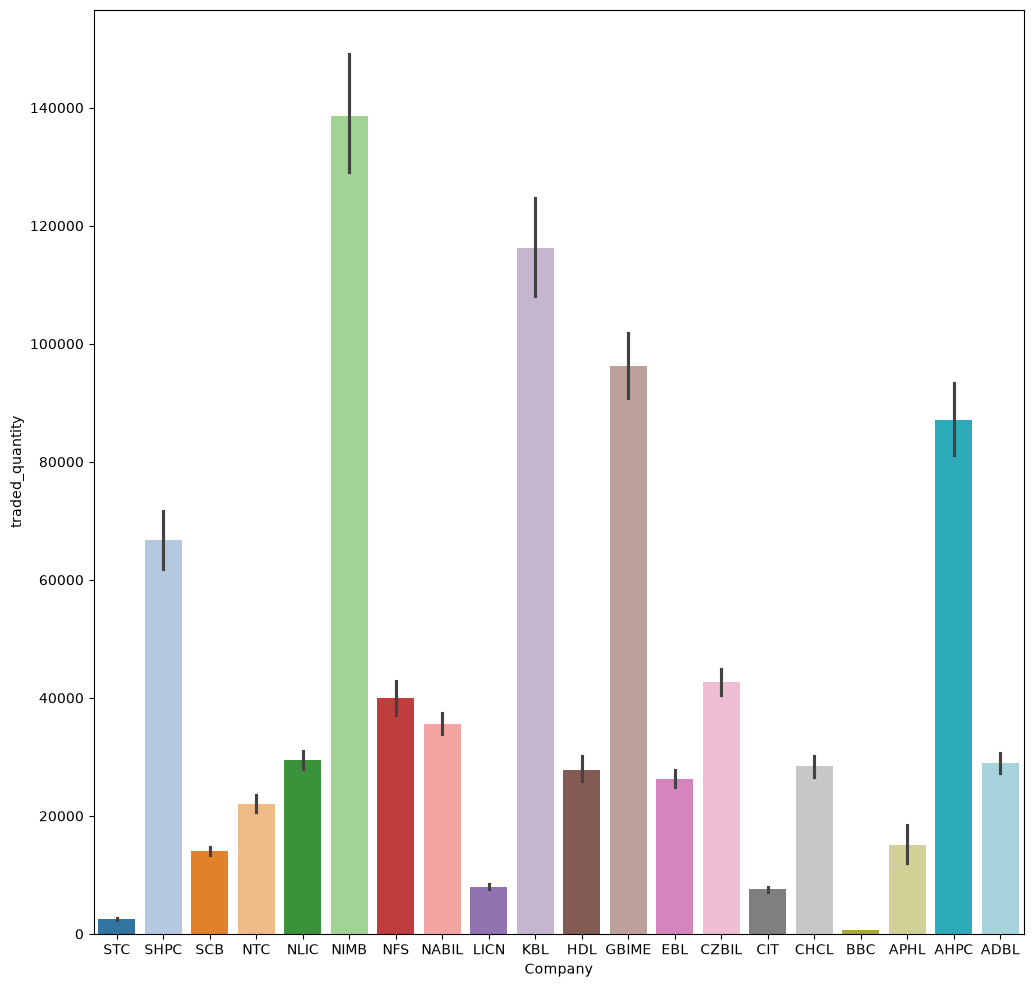

In [163]:

plt.figure(figsize = (12, 12))
sns.barplot(data=master_df, x='Company', y='traded_quantity', palette=twenty_colors)
plt.show()

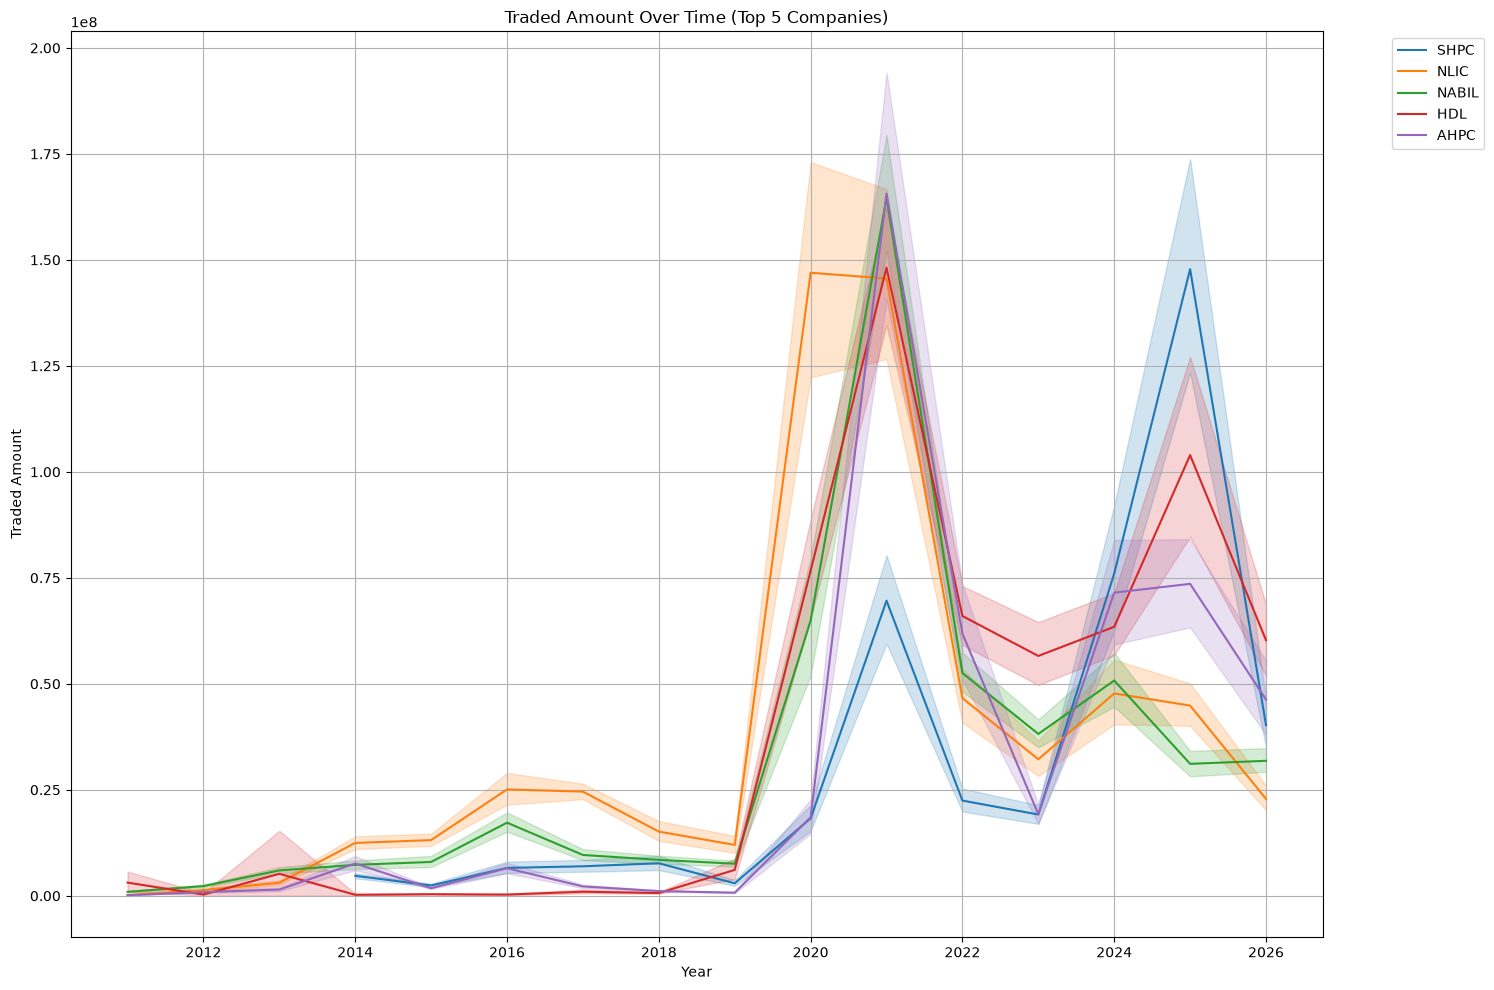

In [130]:
plt.figure(figsize=(15,10))
# 1. Find the top 5 companies by total traded amount
top_5_companies = master_df.groupby('Company')['traded_amount'].sum().nlargest(5).index

# 2. Filter the master DataFrame to keep only rows for these top 5 companies
top_5_df = master_df[master_df['Company'].isin(top_5_companies)]

# 3. Plot the data

sns.lineplot(data=top_5_df, x='year', y='traded_amount', hue='Company')

plt.title('Traded Amount Over Time (Top 5 Companies)')
plt.xlabel('Year')
plt.ylabel('Traded Amount')

# Optional: Move the legend outside the plot so it doesn't overlap the lines
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.grid()

plt.show()

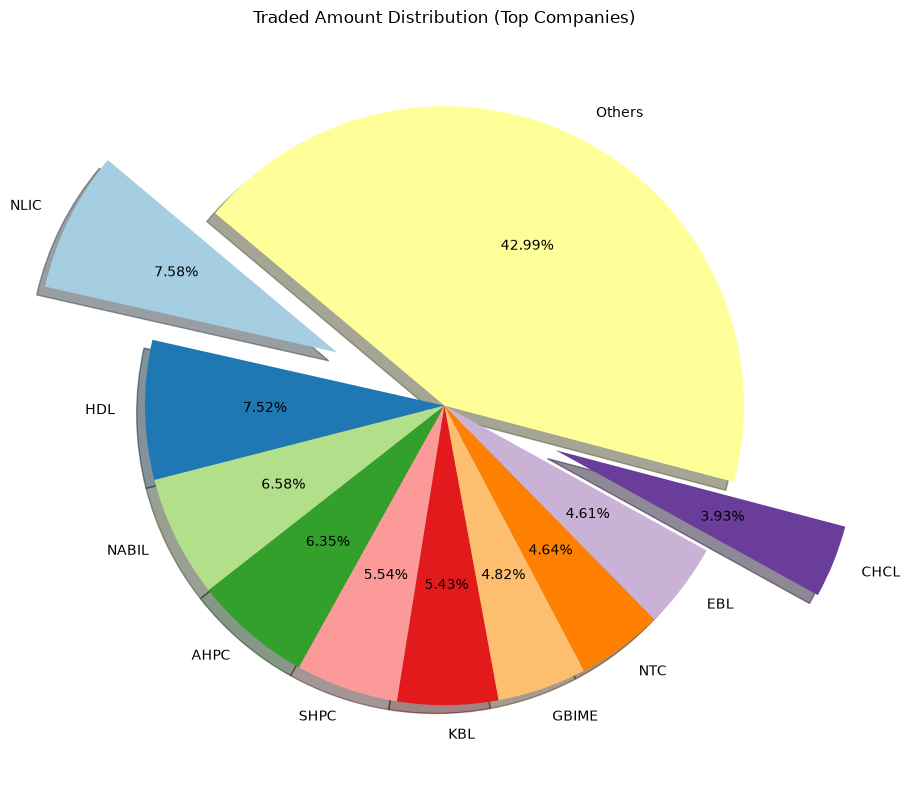

In [146]:
# 1. Group by company and sum the traded amount, then sort descending
company_traded = master_df.groupby('Company')['traded_amount'].sum().sort_values(ascending=False)

# 2. Select the top 5 companies (and optionally group the rest into 'Others')
top_10 = company_traded.head(10)
others_sum = company_traded.iloc[5:].sum()

if others_sum > 0:
    # Append 'Others' category if there are remaining companies
    top_10.loc['Others'] = others_sum

# 3. Create the pie chart
plt.figure(figsize=(10, 8))
plt.pie(
    top_10, 
    labels=top_10.index, 
    autopct='%1.2f%%', 
    startangle=140,
     explode=[0.4,0,0,0,0,0,0,0,0,0.4, 0],
     shadow= True,
    colors=plt.cm.Paired.colors # Uses a nice color palette
    
   
)

plt.title('Traded Amount Distribution (Top Companies)')
plt.ylabel('') # Hides the redundant y-axis label
plt.tight_layout()
plt.show()

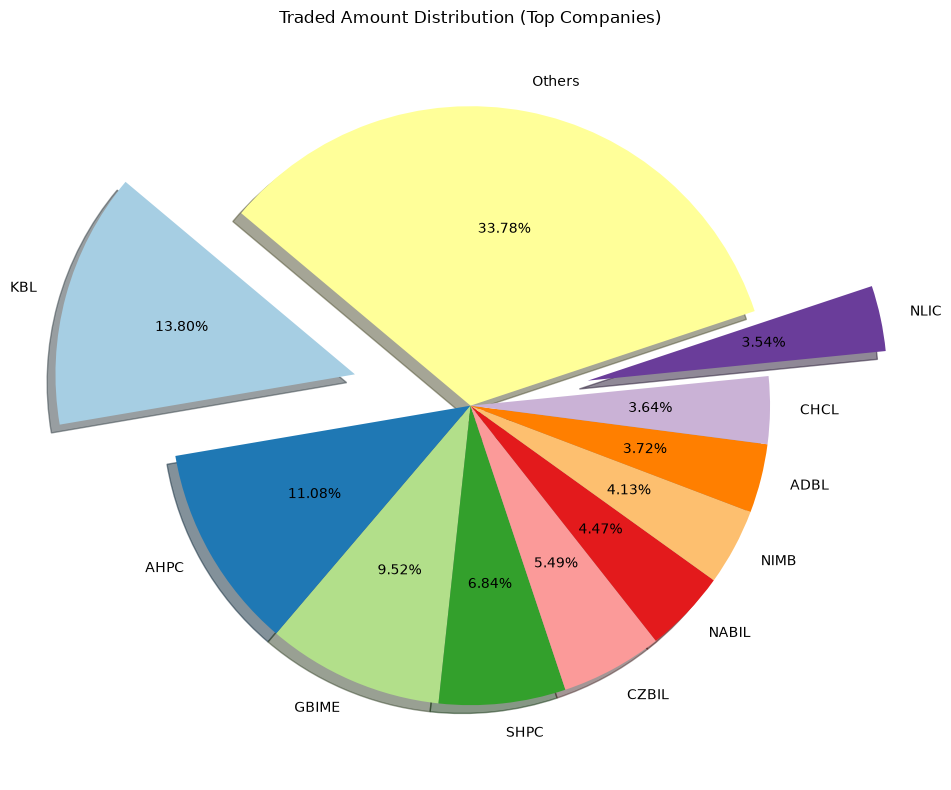

In [161]:
company_traded = master_df.groupby('Company')['traded_quantity'].sum().sort_values(ascending=False)

# 2. Select the top 5 companies (and optionally group the rest into 'Others')
top_10 = company_traded.head(10)
others_sum = company_traded.iloc[5:].sum()

if others_sum > 0:
    # Append 'Others' category if there are remaining companies
    top_10.loc['Others'] = others_sum

# 3. Create the pie chart
plt.figure(figsize=(10, 8))
plt.pie(
    top_10, 
    labels=top_10.index, 
    autopct='%1.2f%%', 
    startangle=140,
     explode=[0.4,0,0,0,0,0,0,0,0,0.4, 0],
     shadow= True,
    colors=plt.cm.Paired.colors # Uses a nice color palette
    
   
)

plt.title('Traded Amount Distribution (Top Companies)')
plt.ylabel('') # Hides the redundant y-axis label
plt.tight_layout()
plt.show()

In [160]:
corrr = master_df.corr(numeric_only=True)
corrr

,open,high,low,close,per_change,traded_quantity,traded_amount,status,year,month,day
open,1.000000,0.999600,0.999714,0.999439,0.000407,-0.178686,0.042244,0.014313,0.005054,-0.001020,0.003581
high,0.999600,1.000000,0.999535,0.999751,0.012208,-0.176923,0.045798,0.019606,0.005612,-0.000907,0.003677
low,0.999714,0.999535,1.000000,0.999694,0.008657,-0.180018,0.039888,0.018467,0.003599,-0.001425,0.003397
close,0.999439,0.999751,0.999694,1.000000,0.018715,-0.178510,0.043169,0.023842,0.003593,-0.001032,0.003554
per_change,0.000407,0.012208,0.008657,0.018715,1.000000,0.087243,0.098889,0.450813,-0.005742,-0.004496,-0.003380
traded_quantity,-0.178686,-0.176923,-0.180018,-0.178510,0.087243,1.000000,0.733166,0.027015,0.286852,-0.011783,0.018098
traded_amount,0.042244,0.045798,0.039888,0.043169,0.098889,0.733166,1.000000,0.038626,0.248646,-0.001293,0.019756
status,0.014313,0.019606,0.018467,0.023842,0.450813,0.027015,0.038626,1.000000,-0.095118,0.011699,0.003819
year,0.005054,0.005612,0.003599,0.003593,-0.005742,0.286852,0.248646,-0.095118,1.000000,-0.058339,-0.001772
month,-0.001020,-0.000907,-0.001425,-0.001032,-0.004496,-0.011783,-0.001293,0.011699,-0.058339,1.000000,0.004252


<Axes: >

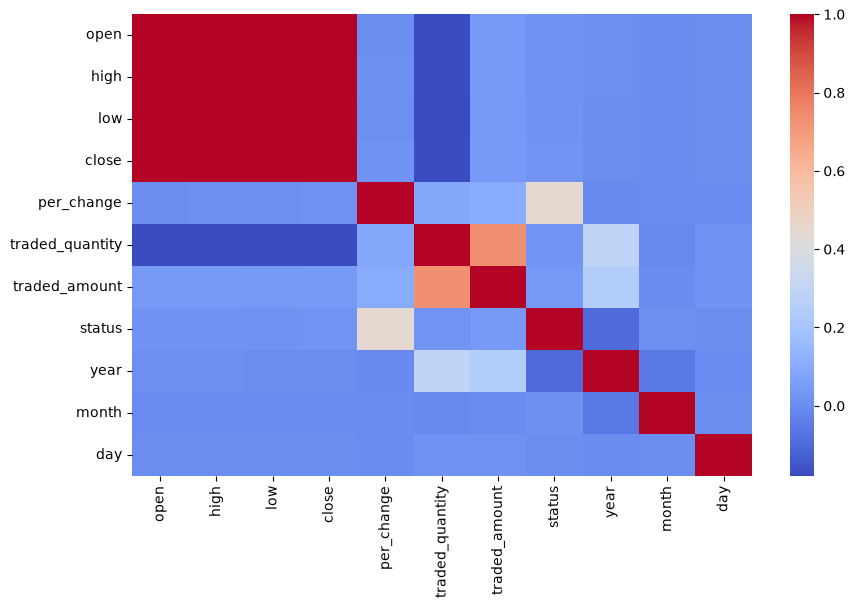

In [158]:
plt.figure(figsize=(10,6))
sns.heatmap(corrr, cmap = 'coolwarm')

# extaction

In [164]:
master_df['per_day_change'] = master_df['high'] - master_df['low']

In [165]:
master_df

,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,month,day,per_day_change
0,5597.0,5597.0,5543.1,5591.0,0.56,347.0,1930122.3,-1,STC,2026,10,16,53.9
1,527.9,536.0,527.0,535.0,1.13,40550.0,21621875.2,1,SHPC,2026,10,16,9.0
2,672.0,679.8,672.0,679.0,0.15,11819.0,8001423.0,1,SCB,2026,10,16,7.8
3,920.0,925.0,915.0,920.0,1.10,19118.0,17559337.2,0,NTC,2026,10,16,10.0
4,740.0,750.0,737.0,743.0,-0.12,12698.0,9461824.6,1,NLIC,2026,10,16,13.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
55504,137.0,131.0,124.0,131.0,-4.38,4755.0,0.0,0,ADBL,2011,1,3,7.0
55505,260.0,261.0,250.0,250.0,-3.85,680.0,0.0,0,CZBIL,2011,1,2,11.0
55506,950.0,950.0,945.0,950.0,0.00,870.0,0.0,0,CHCL,2011,1,2,5.0
55507,447.0,449.0,439.0,439.0,-1.79,466.0,0.0,0,AHPC,2011,1,2,10.0


In [167]:
#drop null
master_df.dropna(inplace= True)

In [171]:
# oneHotEncoder
from sklearn.preprocessing import OneHotEncoder

# Initialize OneHotEncoder
ohe = OneHotEncoder(sparse_output=False, drop='first')

# Fit and transform the 'Company' column (Note the double brackets)
encoded_array = ohe.fit_transform(master_df[['Company']])

# Convert the array into a DataFrame with clean column names
encoded_df = pd.DataFrame(
    encoded_array, 
    columns=ohe.get_feature_names_out(['Company']),
    index=master_df.index # Keeps alignment with your original rows
)

# Join the encoded columns and drop the original 'Company' column
master_df = pd.concat([master_df.drop(columns=['Company']), encoded_df], axis=1)

In [172]:
master_df

,open,high,low,close,per_change,traded_quantity,traded_amount,status,year,month,...,Company_KBL,Company_LICN,Company_NABIL,Company_NFS,Company_NIMB,Company_NLIC,Company_NTC,Company_SCB,Company_SHPC,Company_STC
0,5597.0,5597.0,5543.1,5591.0,0.56,347.0,1930122.3,-1,2026,10,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,527.9,536.0,527.0,535.0,1.13,40550.0,21621875.2,1,2026,10,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,672.0,679.8,672.0,679.0,0.15,11819.0,8001423.0,1,2026,10,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,920.0,925.0,915.0,920.0,1.10,19118.0,17559337.2,0,2026,10,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,740.0,750.0,737.0,743.0,-0.12,12698.0,9461824.6,1,2026,10,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55504,137.0,131.0,124.0,131.0,-4.38,4755.0,0.0,0,2011,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
55505,260.0,261.0,250.0,250.0,-3.85,680.0,0.0,0,2011,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
55506,950.0,950.0,945.0,950.0,0.00,870.0,0.0,0,2011,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
55507,447.0,449.0,439.0,439.0,-1.79,466.0,0.0,0,2011,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# outliers detection

In [178]:
cols = [col for col in master_df.columns[0:12]]
cols[0:12]

['open',
 'high',
 'low',
 'close',
 'per_change',
 'traded_quantity',
 'traded_amount',
 'status',
 'year',
 'month',
 'day',
 'per_day_change']

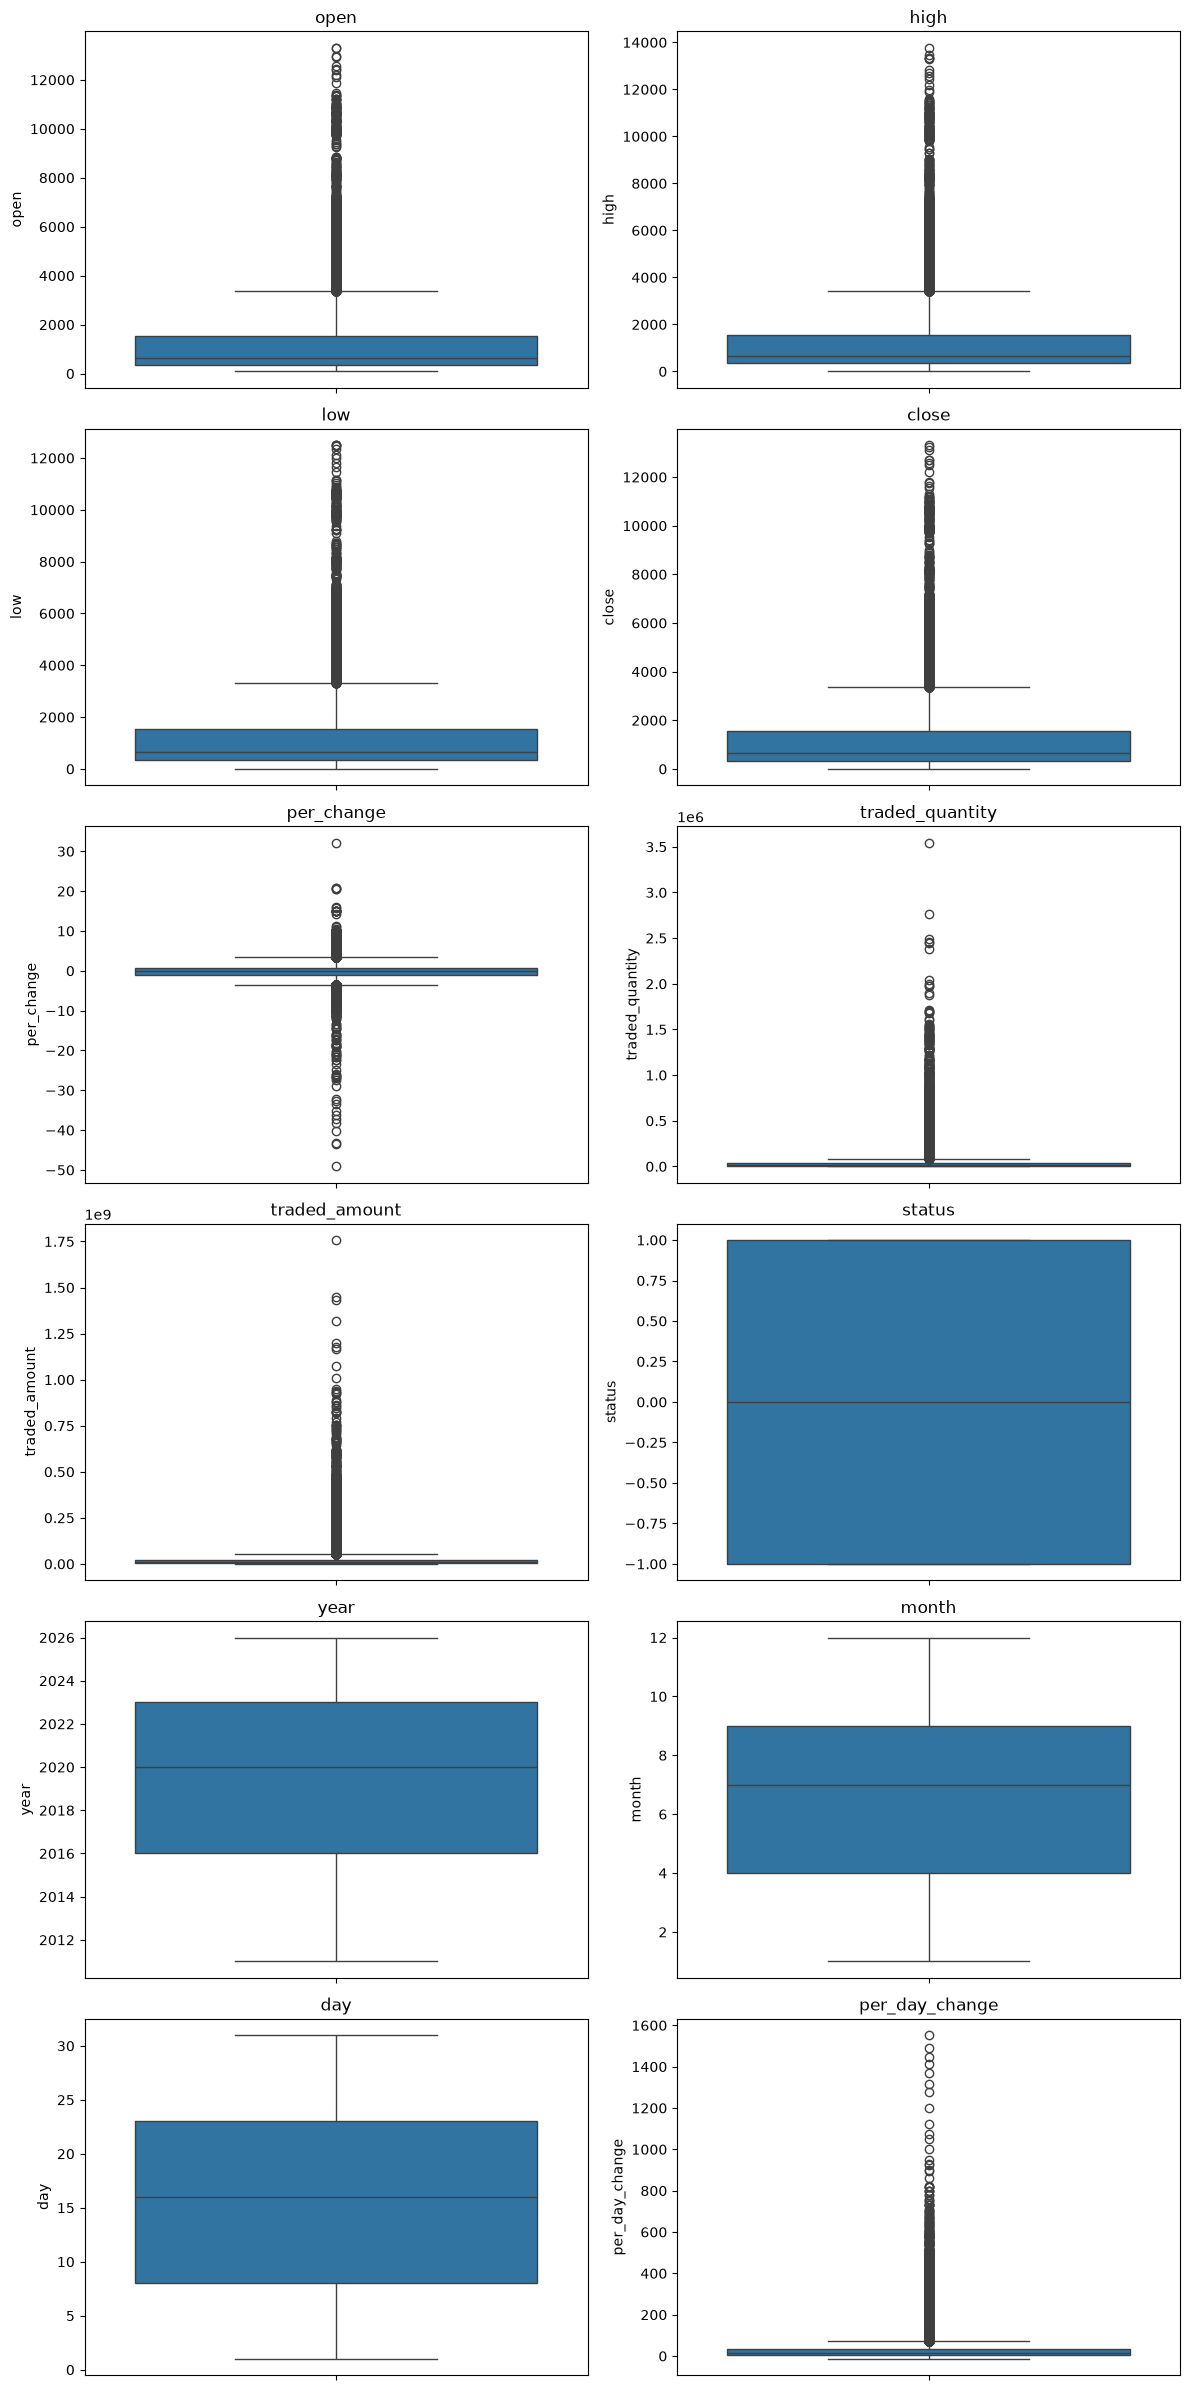

In [184]:
n_cols_grid = 2
n_rows_grid = math.ceil(len(cols) / n_cols_grid)

# Create the subplots figure
fig, axes = plt.subplots(
    n_rows_grid, n_cols_grid, figsize=(12, 4 * n_rows_grid)
)
axes = axes.flatten()  # Flatten to easily loop through axes

for i, col in enumerate(cols):
  sns.boxplot(master_df[col],ax=axes[i])
  axes[i].set_title(col)

# Remove any empty/unused subplots if the grid is larger than len(cols)
for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

- since, this dataset contains outliers, we cannot drop the column

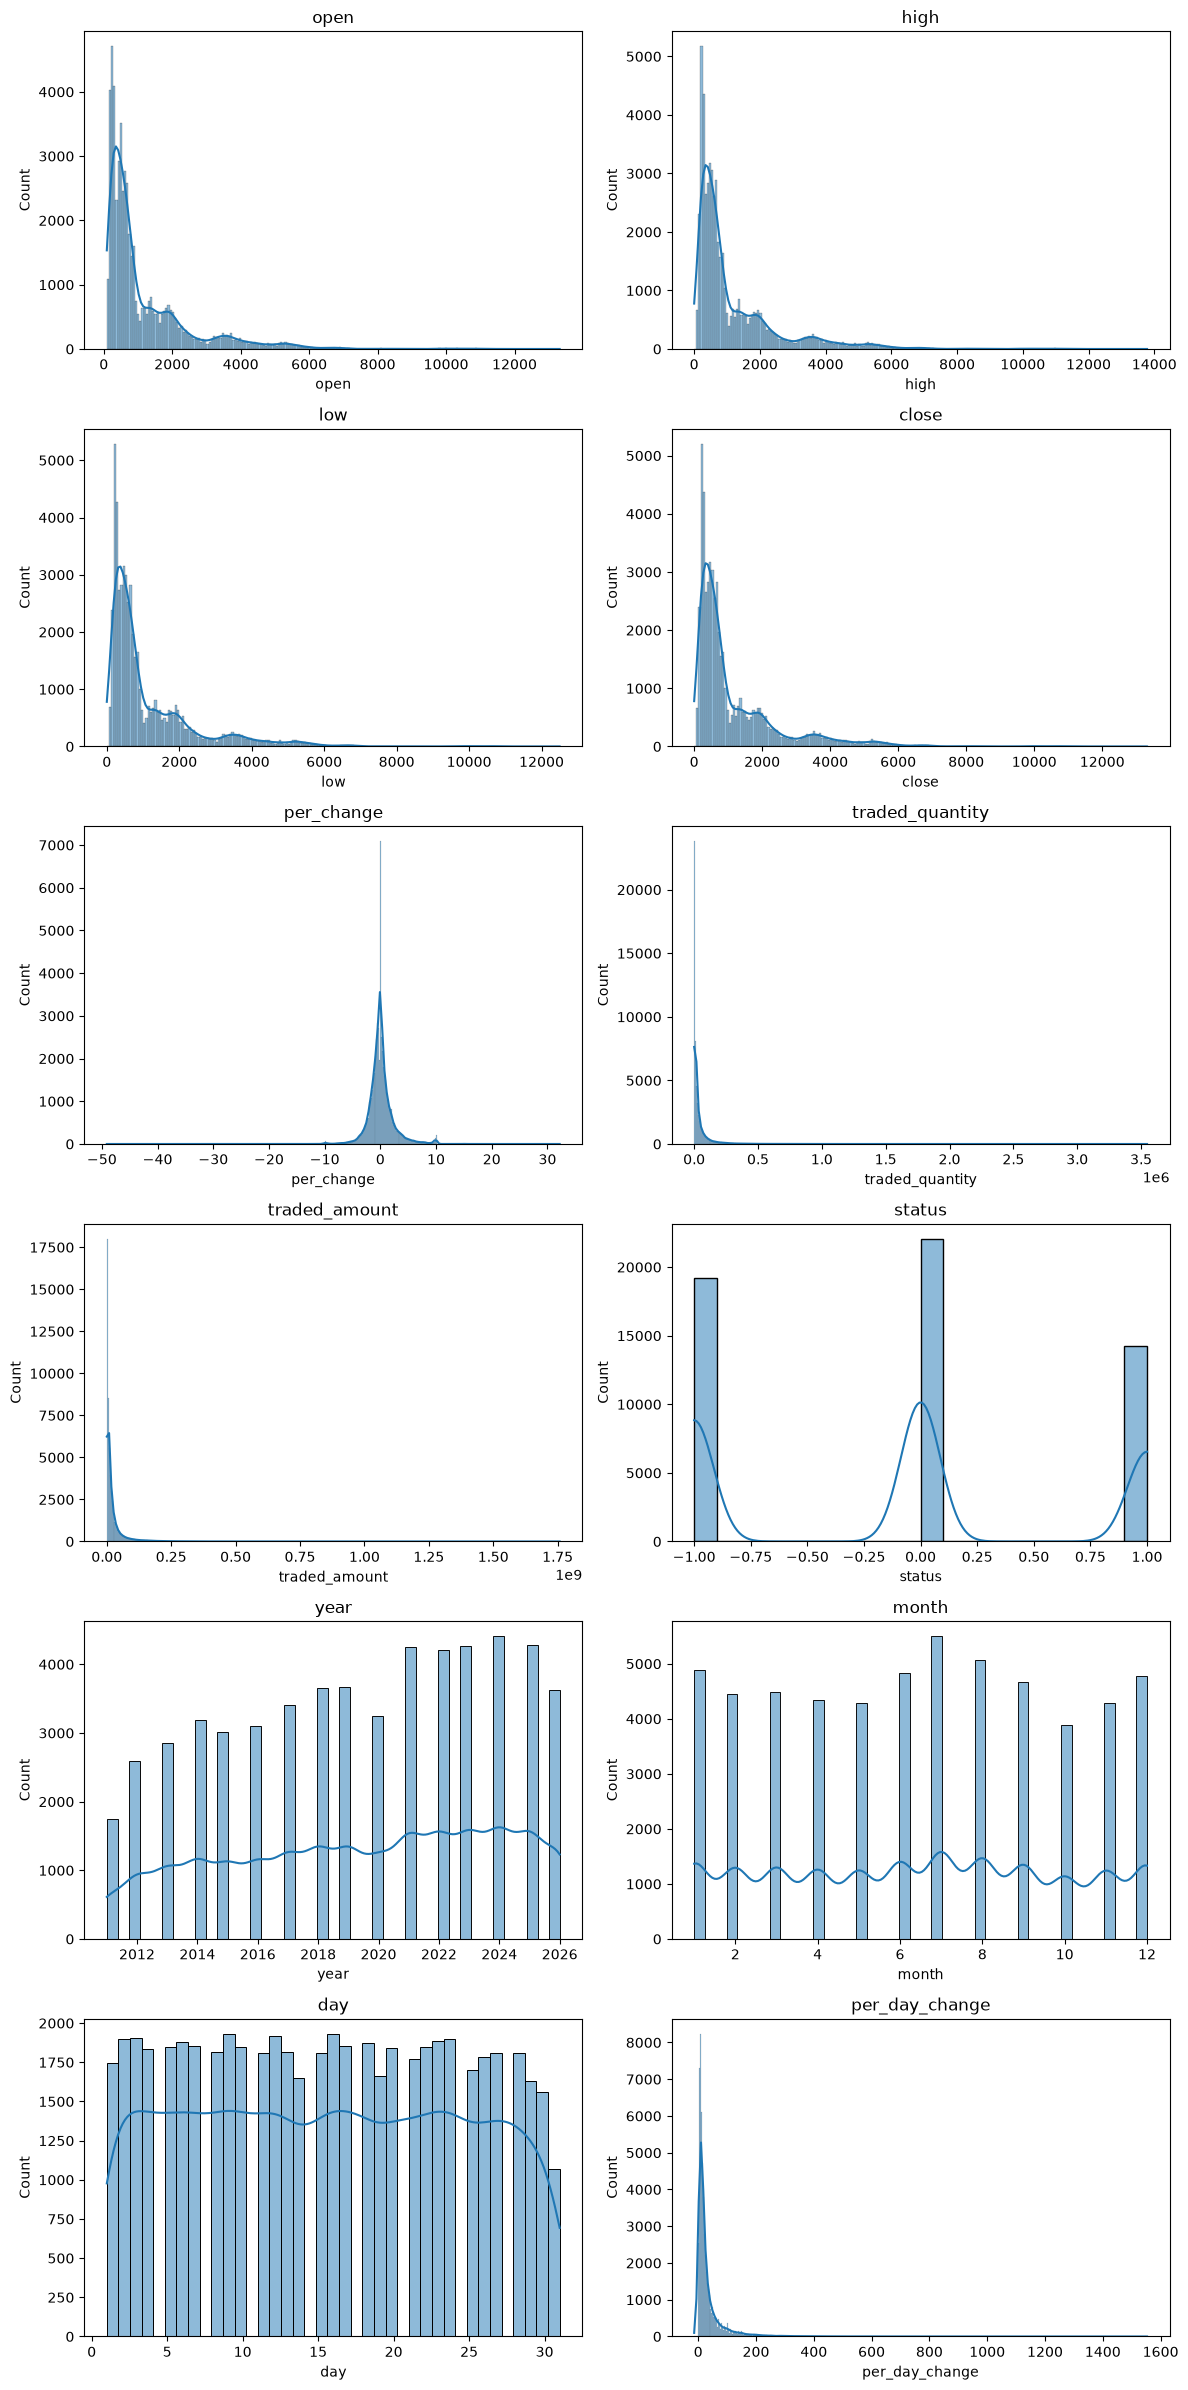

In [183]:
import math


n_cols_grid = 2
n_rows_grid = math.ceil(len(cols) / n_cols_grid)

# Create the subplots figure
fig, axes = plt.subplots(
    n_rows_grid, n_cols_grid, figsize=(12, 4 * n_rows_grid)
)
axes = axes.flatten()  # Flatten to easily loop through axes

for i, col in enumerate(cols):
  sns.histplot(master_df[col], kde=True, ax=axes[i])
  axes[i].set_title(col)

# Remove any empty/unused subplots if the grid is larger than len(cols)
for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# kurtosis
- since the dataset contains lepokutric more. we would apply log transformation or power transformation